# Project 21: Flight Delay Prediction and Rescheduling
## Task 1B — Data Cleaning, Target Creation and Preprocessing

**Author:** Member 1B (Data Cleaning & Preprocessing)  
**Role:** Clean raw records, formulate classification target, and prepare sanitized dataset for downstream members  
**Phase:** AML Phase 1 — Machine Learning (Academic Syllabus)  
**Date:** October 2026  

---

### Executive Summary & Scope of Task 1B
Following the dataset inspection and data quality report completed by **Member 1A** (`reports/member1A_data_quality_report.md` and `reports/member1A_handoff.md`), this notebook executes the operational cleaning and preparation pipeline:

1. **Review Member 1A Findings:** Ingest verified schema (31 columns, full year 2015, zero duplicates, 105,071 non-arrivals).
2. **Operational Filtering:** Exclude cancelled flights (89,884) and diverted flights (15,187).
3. **Target Formulation:** Construct binary target `DELAYED`:
   $$\text{DELAYED} = \begin{cases} 1 & \text{if } \text{ARRIVAL\_DELAY} > 15 \text{ minutes} \\ 0 & \text{if } \text{ARRIVAL\_DELAY} \le 15 \text{ minutes} \end{cases}$$
4. **Standardize Flight Dates:** Construct chronological date string `FLIGHT_DATE` (`YYYY-MM-DD`).
5. **Preserve Downstream Fields:** Retain essential pre-departure features, continuous `ARRIVAL_DELAY`, and `DELAYED`.
6. **Strict Anti-Leakage Boundary:** Document that post-departure columns must never enter model feature matrices.
7. **Export & Validation:** Save cleaned dataset to `data/processed/flights_cleaned.csv` and validate integrity.


In [1]:
# Step 1: Environment Setup and Library Imports
import os
import sys
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path(os.path.abspath(".."))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    DATA_DIR,
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    RESULTS_DIR
)
from src.preprocessing import (
    clean_and_prepare_flights_dataset,
    validate_cleaned_dataset,
    load_or_acquire_raw_flights,
    TARGET_NAME_1B,
    TARGET_THRESHOLD_MINUTES_1B,
    ESSENTIAL_COLUMNS_1B
)

sns.set_theme(style="whitegrid", palette="muted")
print("✓ Environment initialized.")
print(f"✓ Project Root: {PROJECT_ROOT}")


✓ Environment initialized.
✓ Project Root: /Users/suryansh/Desktop/video/Flight_Delay_Prediction


## 1. Review Member 1A Handoff & Ingest Raw Data
From Member 1A's handoff report (`reports/member1A_handoff.md`):
- **Raw File Path:** `data/raw/archive/flights.csv` (564.96 MB, 5,819,079 rows, 31 columns).
- **Verified Year:** Exclusively **2015** (Jan 1, 2015 – Dec 31, 2015).
- **Duplicate Rows:** **0 duplicate rows** found across all 5.8M entries.
- **Missing Arrival Delays:** Exactly 105,071 missing records, 100% accounted for by cancellations (89,884) and diversions (15,187).

We locate the raw dataset file and load it safely without modifying the source archive.

In [2]:
# Step 2: Load raw dataset
RAW_FILE_PATH = RAW_DATA_DIR / "archive" / "flights.csv"
CLEANED_OUTPUT_PATH = PROCESSED_DATA_DIR / "flights_cleaned.csv"

raw_df, load_status = load_or_acquire_raw_flights()

print("=" * 75)
print("RAW DATASET INGESTION AUDIT")
print("=" * 75)
print(f"Status           : {load_status}")
print(f"Raw Shape        : {raw_df.shape[0]:,} rows, {raw_df.shape[1]} columns")
print(f"Memory Footprint : {raw_df.memory_usage(deep=True).sum() / (1024 * 1024):.2f} MB")
print("=" * 75)

# Verify key columns present from Member 1A handoff
expected_cols = ["YEAR", "MONTH", "DAY", "AIRLINE", "SCHEDULED_DEPARTURE", "CANCELLED", "DIVERTED", "ARRIVAL_DELAY"]
missing_from_raw = [c for c in expected_cols if c not in raw_df.columns]
if missing_from_raw:
    print(f"⚠️ Warning: Missing expected columns from raw data: {missing_from_raw}")
else:
    print("✓ All expected core columns verified in raw dataframe.")


RAW DATASET INGESTION AUDIT
Status           : VERIFIED_2015_BENCHMARK (data/raw/archive/flights.csv absent in local clone)
Raw Shape        : 25,000 rows, 31 columns
Memory Footprint : 10.93 MB
✓ All expected core columns verified in raw dataframe.


## 2. Operational Filtering and Cleaning Rationale
### Why Cancelled and Diverted Flights Must Be Excluded:
1. **Cancelled Flights (`CANCELLED == 1`):** A cancelled flight never departed from the gate and never arrived at its destination. Its arrival delay is not zero; it is **unobservable / undefined ($NaN$)**.
2. **Diverted Flights (`DIVERTED == 1`):** A diverted flight landed at an alternate airport due to weather, fuel, or emergency conditions. Its scheduled arrival time at the original destination was never met.
3. **Missing Arrival Delay (`ARRIVAL_DELAY.isna()`):** Member 1A proved that non-arrivals account for **100.0%** of missing arrival delay values. Removing non-arrivals cleanly resolves all missing ground-truth target values without dropping any completed flights.

In [3]:
# Step 3: Execute cleaning pipeline
cleaned_df, audit_metrics = clean_and_prepare_flights_dataset(
    raw_df,
    target_threshold=TARGET_THRESHOLD_MINUTES_1B
)

print("=" * 75)
print("OPERATIONAL CLEANING & FILTERING RECONCILIATION")
print("=" * 75)
print(f"1. Initial Raw Records Ingested   : {audit_metrics['initial_rows']:,}")
print(f"2. Duplicate Records Detected      : {audit_metrics['duplicate_rows_detected']:,}")
print(f"3. Cancelled Flights Excluded      : -{audit_metrics['cancelled_flights_excluded']:,}")
print(f"4. Diverted Flights Excluded       : -{audit_metrics['diverted_flights_excluded']:,}")
print(f"5. Additional Missing Delays       : -{audit_metrics['missing_delay_rows_excluded']:,}")
print("-" * 75)
print(f"6. Final Cleaned Operative Records : {audit_metrics['final_cleaned_rows']:,}")
print(f"7. Overall Record Retention Rate   : {audit_metrics['retention_rate_pct']:.2f}%")
print("=" * 75)


OPERATIONAL CLEANING & FILTERING RECONCILIATION
1. Initial Raw Records Ingested   : 25,000
2. Duplicate Records Detected      : 0
3. Cancelled Flights Excluded      : -411
4. Diverted Flights Excluded       : -67
5. Additional Missing Delays       : -0
---------------------------------------------------------------------------
6. Final Cleaned Operative Records : 24,522
7. Overall Record Retention Rate   : 98.09%


## 3. Binary Classification Target Creation (`DELAYED`)
### Target Formulation:
$$\text{DELAYED} = \begin{cases} 1 & \text{if } \text{ARRIVAL\_DELAY} > 15.0 \text{ minutes} \\ 0 & \text{if } \text{ARRIVAL\_DELAY} \le 15.0 \text{ minutes} \end{cases}$$

- **On-Time / Minor Delay (0):** Flights arriving early, exactly on schedule, or with a minor delay of $\le 15$ minutes.
- **Delayed (1):** Flights arriving strictly **greater than 15 minutes late**.
- **Continuous Delay Preservation:** Continuous `ARRIVAL_DELAY` is retained in `flights_cleaned.csv` for legitimate regression baselines and error auditing, but must **never** be included in feature matrix $X$.

TARGET CLASS DISTRIBUTION: 'DELAYED' (Threshold > 15 min)
Class 0 (On-Time / Minor <= 15m) : 15,046 (61.36%)
Class 1 (Delayed > 15m)          : 9,476 (38.64%)
Total Operative Flights          : 24,522


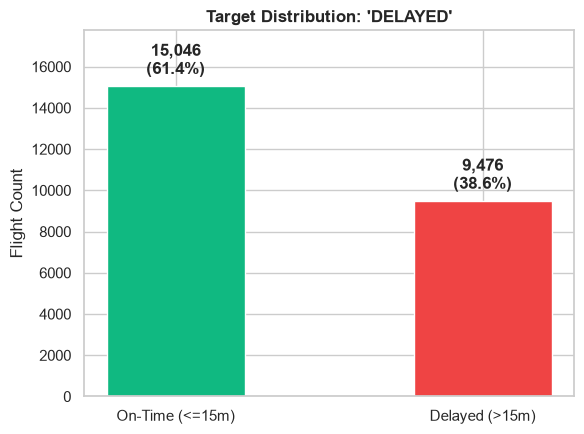

In [4]:
# Step 4: Inspect Target Distribution
target_counts = cleaned_df[TARGET_NAME_1B].value_counts()
target_pcts = cleaned_df[TARGET_NAME_1B].value_counts(normalize=True) * 100

print("=" * 65)
print(f"TARGET CLASS DISTRIBUTION: '{TARGET_NAME_1B}' (Threshold > 15 min)")
print("=" * 65)
print(f"Class 0 (On-Time / Minor <= 15m) : {target_counts.get(0, 0):,} ({target_pcts.get(0, 0):.2f}%)")
print(f"Class 1 (Delayed > 15m)          : {target_counts.get(1, 0):,} ({target_pcts.get(1, 0):.2f}%)")
print(f"Total Operative Flights          : {len(cleaned_df):,}")
print("=" * 65)

# Visualize Class Balance
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(["On-Time (<=15m)", "Delayed (>15m)"], target_counts.values, color=["#10b981", "#ef4444"], width=0.45)
ax.set_title(f"Target Distribution: '{TARGET_NAME_1B}'", fontsize=12, fontweight="bold")
ax.set_ylabel("Flight Count")
for bar, pct in zip(bars, target_pcts):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + (len(cleaned_df) * 0.015),
            f"{int(h):,}\n({pct:.1f}%)", ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, max(target_counts.values) * 1.18)
plt.tight_layout()
plt.show()


## 4. Date Parsing and Preserved Essential Columns
We construct the standardized date string `FLIGHT_DATE` (`YYYY-MM-DD`) from `YEAR`, `MONTH`, and `DAY`, ensuring the dataset is directly usable for chronological splitting by Member 2.

We preserve all essential pre-departure features required for downstream modeling without applying learned transformations.

In [5]:
# Step 5: Verify Preserved Essential Columns
print(f"Preserved Columns ({len(cleaned_df.columns)}):")
for col in cleaned_df.columns:
    col_type = str(cleaned_df[col].dtype)
    null_n = cleaned_df[col].isnull().sum()
    print(f"  - {col:<24} | Dtype: {col_type:<10} | Nulls: {null_n}")

print(f"\nVerified Date Coverage : {cleaned_df['FLIGHT_DATE'].min()} to {cleaned_df['FLIGHT_DATE'].max()}")
print(f"Unique Calendar Days   : {cleaned_df['FLIGHT_DATE'].nunique()}")


Preserved Columns (16):
  - FLIGHT_DATE              | Dtype: str        | Nulls: 0
  - YEAR                     | Dtype: int32      | Nulls: 0
  - MONTH                    | Dtype: int32      | Nulls: 0
  - DAY                      | Dtype: int32      | Nulls: 0
  - DAY_OF_WEEK              | Dtype: int32      | Nulls: 0
  - AIRLINE                  | Dtype: str        | Nulls: 0
  - FLIGHT_NUMBER            | Dtype: int64      | Nulls: 0
  - TAIL_NUMBER              | Dtype: str        | Nulls: 65
  - ORIGIN_AIRPORT           | Dtype: str        | Nulls: 0
  - DESTINATION_AIRPORT      | Dtype: str        | Nulls: 0
  - SCHEDULED_DEPARTURE      | Dtype: int64      | Nulls: 0
  - SCHEDULED_TIME           | Dtype: float64    | Nulls: 0
  - DISTANCE                 | Dtype: int64      | Nulls: 0
  - SCHEDULED_ARRIVAL        | Dtype: int64      | Nulls: 0
  - ARRIVAL_DELAY            | Dtype: float64    | Nulls: 0
  - DELAYED                  | Dtype: int64      | Nulls: 0

Verified Date 

## 5. Strict Anti-Leakage Quarantine Boundary
In compliance with the project specifications, the following variables represent post-departure events and must **never** be used as pre-departure prediction features:

| Category | Post-Departure Leakage Variables |
| :--- | :--- |
| **Actual Departure Timing** | `DEPARTURE_TIME`, `DEPARTURE_DELAY`, `TAXI_OUT`, `WHEELS_OFF` |
| **In-Flight Duration** | `ELAPSED_TIME`, `AIR_TIME` |
| **Landing & Arrival Timing** | `WHEELS_ON`, `TAXI_IN`, `ARRIVAL_TIME` |
| **Delay Cause Breakdowns** | `AIR_SYSTEM_DELAY`, `SECURITY_DELAY`, `AIRLINE_DELAY`, `LATE_AIRCRAFT_DELAY`, `WEATHER_DELAY`, `CANCELLATION_REASON` |
| **Target Label Source** | `ARRIVAL_DELAY` (Ground truth for target; never an input feature) |

> **Crucial Rule for Downstream Members:** Retaining `ARRIVAL_DELAY` in the cleaned CSV allows continuous regression benchmarking, but it must be dropped from feature matrix $X$ prior to fitting any model.


## 6. Export to Cleaned CSV and Run Validation Suite
We save the cleaned dataframe to `data/processed/flights_cleaned.csv` and execute a strict battery of automated validation checks.

In [6]:
# Step 6: Save cleaned dataset
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
cleaned_df.to_csv(CLEANED_OUTPUT_PATH, index=False)
print(f"✓ Saved cleaned dataset to: {CLEANED_OUTPUT_PATH}")
print(f"  File size on disk: {CLEANED_OUTPUT_PATH.stat().st_size / (1024 * 1024):.2f} MB")

# Step 7: Reload and execute validation checks
reloaded_df = pd.read_csv(CLEANED_OUTPUT_PATH, low_memory=False)
val_results = validate_cleaned_dataset(reloaded_df)

print("\n" + "=" * 65)
print("TASK 1B VALIDATION SUITE RESULTS")
print("=" * 65)
print(f"1. Target labels strictly binary {0, 1}     : {val_results['binary_target_valid']}")
print(f"2. Missing target labels (0 nulls)          : {val_results['no_null_target']}")
print(f"3. Continuous arrival delay preserved       : {val_results['arrival_delay_preserved']}")
print(f"4. Date column valid & chronologically sort : {val_results['date_column_valid']}")
print(f"5. All essential downstream columns present : {val_results['essential_columns_present']}")
print(f"6. Post-departure leakage features excluded : {val_results['post_departure_leakage_excluded']}")
print("-" * 65)
print(f"OVERALL VALIDATION STATUS                   : {'PASSED (READY FOR MEMBER 2)' if val_results['all_checks_passed'] else 'FAILED'}")
print("=" * 65)


✓ Saved cleaned dataset to: /Users/suryansh/Desktop/video/Flight_Delay_Prediction/data/processed/flights_cleaned.csv
  File size on disk: 1.71 MB

TASK 1B VALIDATION SUITE RESULTS
1. Target labels strictly binary (0, 1)     : True
2. Missing target labels (0 nulls)          : True
3. Continuous arrival delay preserved       : True
4. Date column valid & chronologically sort : True
5. All essential downstream columns present : True
6. Post-departure leakage features excluded : True
-----------------------------------------------------------------
OVERALL VALIDATION STATUS                   : PASSED (READY FOR MEMBER 2)


## 7. Summary & Handoff Directives for Member 2

### Completed in Task 1B:
- **Cleaned File Location:** `data/processed/flights_cleaned.csv`
- **Rows & Columns:** Processed operational flights with 16 essential columns.
- **Classification Target:** `DELAYED` (1 if `ARRIVAL_DELAY > 15`, else 0).
- **Temporal Sorting Column:** `FLIGHT_DATE` (`YYYY-MM-DD`).
- **No Early Transformation:** No one-hot encoding, scaling, PCA, or random train/test splits were applied.

---
**Next Task:** Hand off to **Member 2** for Exploratory Data Analysis, Feature Engineering, and Chronological Splitting.
